# Portfolio protection · historical evidence
**Research notebook 01 | Published benchmarks | 2014–2025**

Does protection deliver more than simply reducing equity exposure? This notebook reads the committed research outputs, compares return and downside outcomes, and examines the data audit. It runs offline; optional source reproduction is explicit below.

**Boundaries:** PPUT and CLL are hypothetical Cboe indices. SPY adjusted prices are an ETF total-return proxy. Monthly observations support the long comparison; a separate complete daily sample supports 2021–2025 drawdowns. Neither is a custom option-chain backtest.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT / "hedgelab").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "hedgelab").is_dir(), "Launch from the repository or notebooks directory"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.15, "font.size": 11})
pd.set_option("display.max_columns", 12)
COLORS = ["#223e5a", "#007f82", "#bd6634", "#7e739e"]

## 1 · Verify the evidence and frequency

In [2]:
RESULTS = ROOT / "results/historical"
summary = pd.read_csv(RESULTS / "summary.csv")
daily = pd.read_csv(RESULTS / "daily_validation.csv").set_index("strategy")
config = json.loads((RESULTS / "config.json").read_text())
provenance = json.loads((RESULTS / "provenance.json").read_text())
assert config["frequency"] == "month-end"
assert (daily.sessions == 1255).all()
display(Markdown(f"**{provenance['level_rows']} month-end levels**, including the base close; **{len(provenance['source_calendar_issues'])} source-calendar exceptions** audited before selecting the observation frequency."))
display(pd.Series(config["risk_matched_weights"], name="Frozen equity weight").to_frame().style.format("{:.1%}"))

**145 month-end levels**, including the base close; **50 source-calendar exceptions** audited before selecting the observation frequency.

,Frozen equity weight
PPUT,76.1%
CLL,71.4%


## 2 · Daily validation: return versus downside
Daily figures reset each portfolio at the 2020 year-end close and include initial control funding costs. Cash controls rebalance monthly. The risk weights were fitted using monthly development returns through 2020.

,CAGR,volatility,max_drawdown,Sharpe_excess_cash
strategy,,,,
PPUT,9.31%,13.17%,-22.14%,0.49
CLL,9.12%,11.82%,-17.23%,0.52
SPY,14.38%,17.12%,-24.50%,0.68
half_equity_cash,9.03%,8.49%,-12.44%,0.67
PPUT_risk_matched,11.87%,12.97%,-18.85%,0.68
CLL_risk_matched,11.36%,12.16%,-17.71%,0.68
cash,3.33%,0.15%,0.00%,-0.00


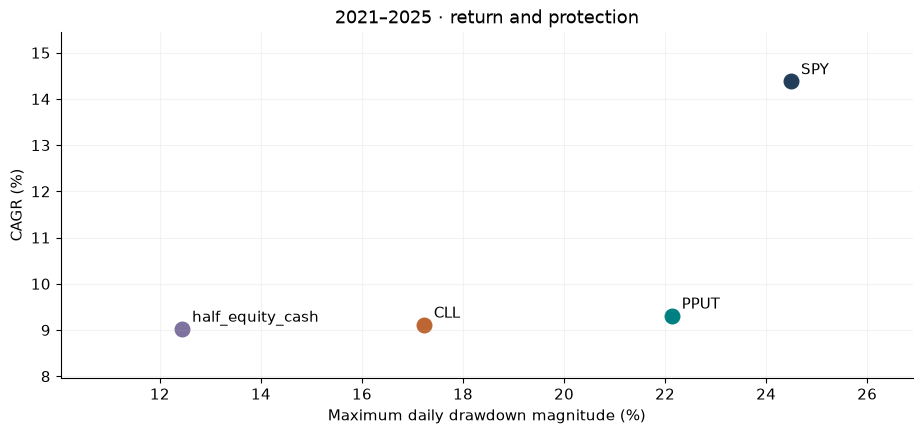

In [3]:
columns = ["CAGR", "volatility", "max_drawdown", "Sharpe_excess_cash"]
display(daily[columns].style.format({"CAGR":"{:.2%}", "volatility":"{:.2%}", "max_drawdown":"{:.2%}", "Sharpe_excess_cash":"{:.2f}"}))
fig, ax = plt.subplots()
for i, name in enumerate(["SPY", "PPUT", "CLL", "half_equity_cash"]):
    row = daily.loc[name]
    ax.scatter(-100 * row.max_drawdown, 100 * row.CAGR, s=110, color=COLORS[i])
    ax.annotate(name, (-100 * row.max_drawdown, 100 * row.CAGR), xytext=(7, 5), textcoords="offset points")
ax.set(xlabel="Maximum daily drawdown magnitude (%)", ylabel="CAGR (%)", title="2021–2025 · return and protection")
ax.margins(.2)
plt.show()

## 3 · Calendar-year outcomes
These annual returns come from the continuous monthly study. The first daily validation investment is a separate reset, so its control funding differs slightly from the continuous study.

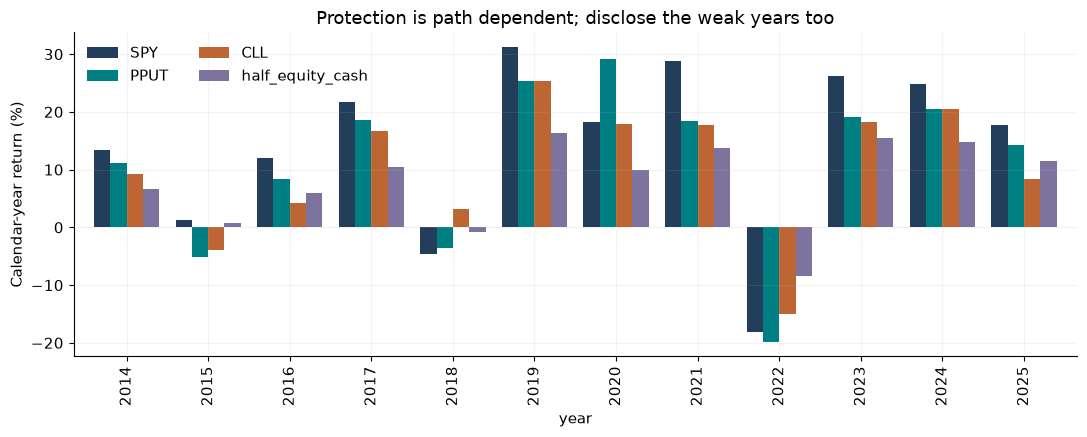

,SPY,PPUT,CLL,half_equity_cash
year,,,,
2020,18.33%,29.08%,17.97%,9.99%
2022,-18.18%,-19.81%,-15.05%,-8.36%


In [4]:
annual = pd.read_csv(RESULTS / "annual_returns.csv", index_col="year")
annual[["SPY", "PPUT", "CLL", "half_equity_cash"]].mul(100).plot.bar(color=COLORS, width=.8)
plt.ylabel("Calendar-year return (%)")
plt.title("Protection is path dependent; disclose the weak years too")
plt.legend(frameon=False, ncol=2)
plt.tight_layout()
plt.show()
display(annual.loc[[2020, 2022], ["SPY", "PPUT", "CLL", "half_equity_cash"]].style.format("{:.2%}"))

## 4 · Uncertainty and drag
The paired three-month block bootstrap estimates annualised arithmetic mean return differences. These are not CAGR confidence intervals, and no multiple-testing correction or untouched holdout is claimed.

In [5]:
intervals = pd.read_csv(RESULTS / "uncertainty.csv")
display(intervals.style.format({c:"{:.2%}" for c in ["annual_mean_difference", "lower_95", "upper_95"]}))
drag = pd.read_csv(RESULTS / "cost_sensitivity.csv")
display(drag.pivot(index="extra_annual_drag_bps", columns="strategy", values="CAGR").style.format("{:.2%}"))

,strategy,reference,annual_mean_difference,lower_95,upper_95
0,PPUT,SPY,-4.85%,-7.57%,-1.96%
1,PPUT,half_equity_cash,0.82%,-3.82%,5.50%
2,PPUT,PPUT_risk_matched,-2.13%,-4.80%,0.37%
3,CLL,SPY,-5.21%,-8.99%,-0.14%
4,CLL,half_equity_cash,0.46%,-4.43%,5.48%
5,CLL,CLL_risk_matched,-1.96%,-5.53%,2.17%


strategy,CLL,PPUT
extra_annual_drag_bps,,
0,9.08%,9.27%
25,8.81%,9.00%
50,8.54%,8.73%
100,7.99%,8.19%


## 5 · Source audit and optional reproduction
Missing trading dates were not filled. Required month-ends and every daily validation date must pass validation. The source bytes are cached privately and hashed. Provider revisions can alter reruns.

In [6]:
audit = pd.DataFrame([{"date": date, "missing_series": ", ".join(series)}
                      for date, series in provenance["source_calendar_issues"].items()])
display(audit.head(10))
REBUILD_FROM_SOURCES = False  # Set True only when you want downloads and a full rerun.
if REBUILD_FROM_SOURCES:
    from hedgelab.historical import run
    run(out=ROOT / "outputs/notebook-history", cache=ROOT / "data/private")
else:
    print("Reviewed archived aggregate evidence; no market-data download performed.")

,date,missing_series
0,2008-09-22,CLL
1,2008-11-21,CLL
2,2008-11-24,CLL
3,2008-11-25,CLL
4,2008-11-26,CLL
5,2008-11-28,CLL
6,2008-12-19,CLL
7,2009-01-16,CLL
8,2009-03-20,CLL
9,2012-04-20,CLL


Reviewed archived aggregate evidence; no market-data download performed.


## Conclusion
The question is not answered by one crash quarter. Compare the option indices with cash dilution, include the years when premiums or capped upside hurt, and distinguish monthly from daily drawdown. Inspect [the research memo](../results/historical/RESEARCH_MEMO.md) for the complete methods and limitations. The [model notebook](02_hedge_experiments.ipynb) examines custom sizing without pretending the simulated paths are historical executions.